In [3]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20244081105
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] hw_env
[学号]       20244081105
[机器指纹] f53f41751d7730eb
[RUN_ID]   20244081105-f53f41751d7730eb


#### 围绕半圆定律

任务1
wigner_density(0) = 0.3183
wigner_density(3) = 0.0
wigner_density([0, 1.5]) = [0.31830989 0.2105422 ]


任务2
生成 5x5 Wigner 矩阵形状: (5, 5)
矩阵是否对称: True
矩阵元素整体方差（近似）: 0.1846 (理论值 1/5 = 0.2000)


任务3
测试矩阵: 
[[1 2]
 [2 1]]
特征值 (非递减): [-1.  3.]


任务4


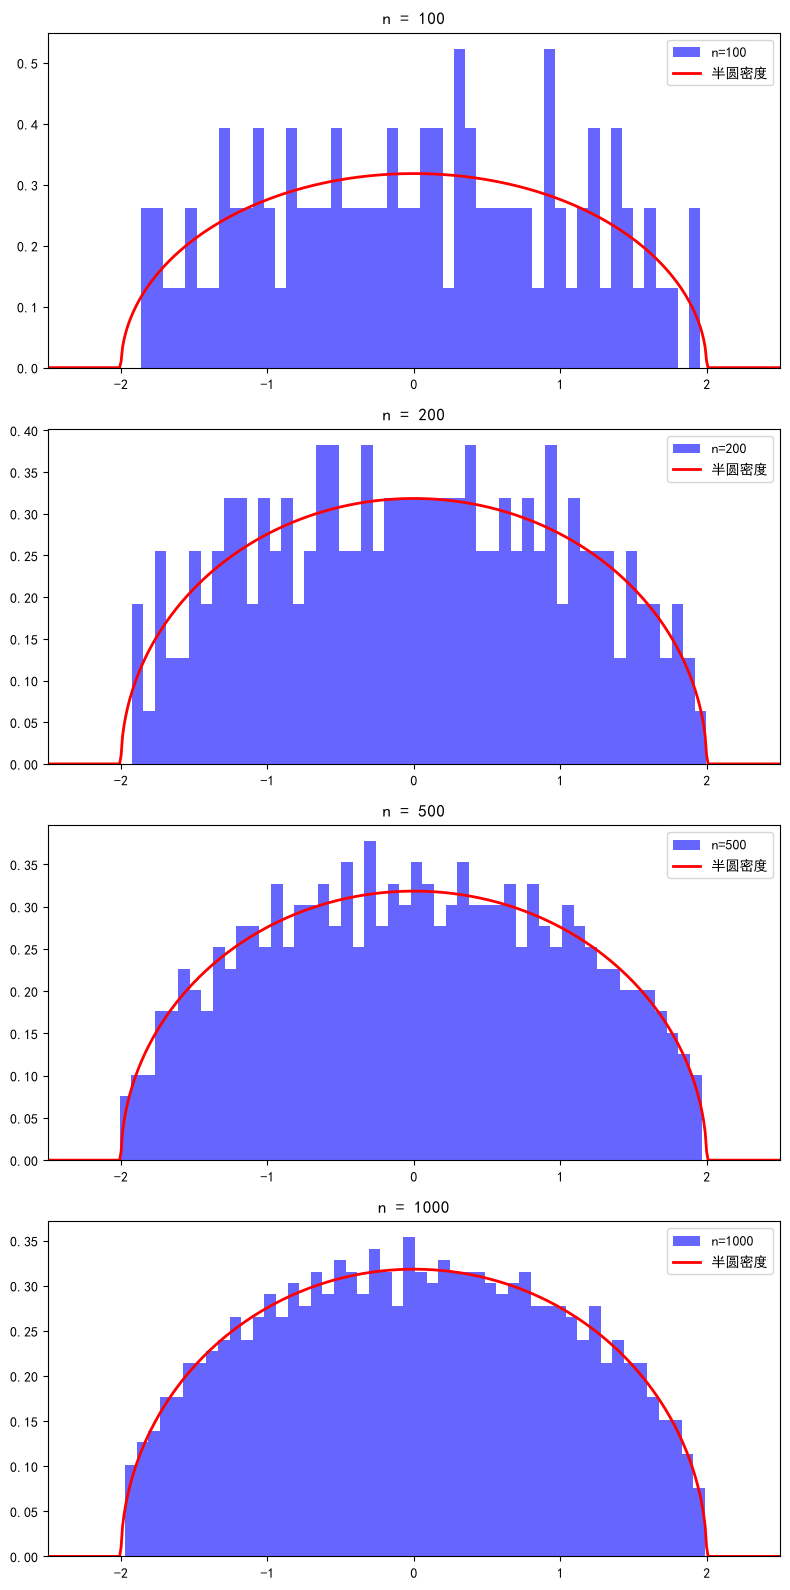

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kstest


plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'PingFang SC', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False 

# 任务 1
def wigner_density(x):
    x_arr = np.asarray(x)
   
    inside = np.clip(4 - x_arr**2, 0, None)
    result = np.where(
        np.abs(x_arr) <= 2,
        (1 / (2 * np.pi)) * np.sqrt(inside),  
        0.0
    )
    
    
    if np.isscalar(x):
        return float(result)
    return result

print("任务1")
print(f"wigner_density(0) = {wigner_density(0):.4f}")  
print(f"wigner_density(3) = {wigner_density(3)}")     
print(f"wigner_density([0, 1.5]) = {wigner_density([0, 1.5])}")
print("\n")

# 任务 2 
def generate_wigner(n):
   
    if not isinstance(n, (int, np.integer)):
        raise TypeError("输入必须是整数")
    if n <= 0:
        raise ValueError("输入必须是正整数")
    
    Z = np.random.randn(n, n)
    upper_triangular = np.triu(Z)
    Z_symmetric = upper_triangular + upper_triangular.T - np.diag(np.diag(Z))
    
    
    Z_scaled = Z_symmetric * (1 / np.sqrt(n))
    
    return Z_scaled

print("任务2")
n_test = 5
W = generate_wigner(n_test)
print(f"生成 {n_test}x{n_test} Wigner 矩阵形状: {W.shape}")
print(f"矩阵是否对称: {np.allclose(W, W.T)}")
print(f"矩阵元素整体方差（近似）: {np.var(W):.4f} (理论值 1/{n_test} = {1/n_test:.4f})")
print("\n")



# 任务3

def get_spectrum(matrix):
    eigenvalues = np.linalg.eigvalsh(matrix)

    eigenvalues_sorted = np.sort(eigenvalues)
    return eigenvalues_sorted

print("任务3")

test_matrix = np.array([[1, 2], [2, 1]])
spectrum = get_spectrum(test_matrix)
print(f"测试矩阵: \n{test_matrix}")
print(f"特征值 (非递减): {spectrum}") 
print("\n")



# 任务4

print("任务4")
n_values = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(8, 16))

for i, n in enumerate(n_values):
    ax = axes[i]
    
    W = generate_wigner(n)
    eigvals = get_spectrum(W)
    ax.hist(eigvals, bins=50, density=True, color='blue', alpha=0.6, label=f'n={n}')

    x_vals = np.linspace(-2.5, 2.5, 500)
    y_vals = wigner_density(x_vals)
    ax.plot(x_vals, y_vals, color='red', linewidth=2, label='半圆密度')

    ax.set_title(f'n = {n}')
    ax.set_xlim(-2.5, 2.5)
    ax.legend()

    def wigner_cdf(x):
        pass
        
    valid_eigs = eigvals[(eigvals >= -2) & (eigvals <= 2)]
    if len(valid_eigs) > 0:
        pass

plt.tight_layout()
plt.show()



从图中可以观察到：随着 n 增大（从 100 到 1000），特征值的直方图越来越接近红色的半圆密度曲线。
大约在 n=500 或 n=1000 时，拟合效果已经比较好。
对于较大的 n，计算特征值会变慢（例如 n=1000 时矩阵为 1000x1000）。

### Conway 的生命游戏

任务1
is_valid_board(test1_1): True
is_valid_board(test1_2): False
is_valid_board(test1_3): False
is_valid_board(test1_4): False

任务2
原始棋盘：
[[0 0 0]
 [1 1 1]
 [0 0 0]]
演化一步后：
[[1 1 1]
 [1 1 1]
 [1 1 1]]

任务3


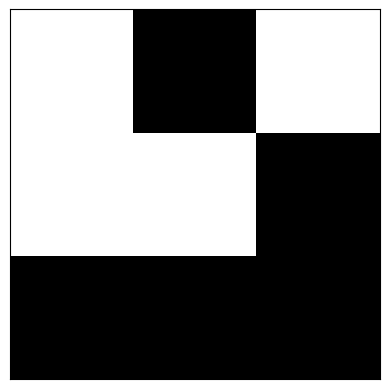

In [4]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'PingFang SC', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# 任务1
def is_valid_board(board):
   
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
   
    return np.all(np.isin(board, [0, 1]))

print("任务1")
test1_1 = np.array([[0, 1, 0], [1, 0, 1]])
test1_2 = np.array([[0, 2, 0], [1, 0, 1]])
test1_3 = np.array([0,1,0])
test1_4 = [[0,1],[1,0]]
print(f"is_valid_board(test1_1): {is_valid_board(test1_1)}")
print(f"is_valid_board(test1_2): {is_valid_board(test1_2)}")
print(f"is_valid_board(test1_3): {is_valid_board(test1_3)}")
print(f"is_valid_board(test1_4): {is_valid_board(test1_4)}")
print()


# 任务2
def gol_step(board):
    
    if not is_valid_board(board):
        raise ValueError("输入不是有效的生命游戏棋盘")
    
    m, n = board.shape
    neighbor_count = np.zeros_like(board)
    
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            
            shifted = np.roll(np.roll(board, di, axis=0), dj, axis=1)
            neighbor_count += shifted
    
    
    survive = (board == 1) & ((neighbor_count == 2) | (neighbor_count == 3))
   
    birth = (board == 0) & (neighbor_count == 3)

    next_board = np.zeros_like(board)
    next_board[survive | birth] = 1
    return next_board

print("任务2")
blinker = np.array([
    [0, 0, 0],
    [1, 1, 1],
    [0, 0, 0]
])
print("原始棋盘：")
print(blinker)
blinker_next = gol_step(blinker)
print("演化一步后：")
print(blinker_next)
print()


# 任务3
def draw_gol_board(board):
   
    plt.imshow(board, cmap="binary", vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.show()

print("任务3")
test_board = np.array([
    [0, 1, 0],
    [0, 0, 1],
    [1, 1, 1]
])
draw_gol_board(test_board)


#### 使⽤ pandas DataFrame

In [7]:
import pandas as pd

FILE_PATH = r"D:\study\数据分析\Iris.csv"
OUT_PATH  = r"D:\study\数据分析\iris_corrected.csv"

df = pd.read_csv(FILE_PATH)

df = df.rename(columns={
    "SepalLengthCm": "sepal_length",
    "SepalWidthCm":  "sepal_width",
    "PetalLengthCm": "petal_length",
    "PetalWidthCm":  "petal_width",
    "Species":       "species"
})
df["species"] = df["species"].str.replace("Iris-", "", regex=False)

print("任务1")
print("数据点总数（行数）：", df.shape[0])
print("列名：", df.columns.tolist())
print("\n每列数据类型：")
print(df.dtypes)
species_unique = df["species"].unique()
print("\n花卉种类数量：", len(species_unique))
print("花卉种类：", species_unique.tolist())
print()


# 任务2
df.loc[34] = [35, 4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37] = [38, 4.9, 3.6, 1.4, 0.1, "setosa"]

print("任务2")
print("索引34 修改后：")
print(df.loc[34])
print("\n索引37 修改后：")
print(df.loc[37])
print()


# 任务3
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

print("任务3")
print(df[["petal_length", "petal_width", "Petal.Ratio",
          "sepal_length", "sepal_width", "Sepal.Ratio"]].head())
print()


# 任务4
df.to_csv(OUT_PATH, index=False)
print("任务4")
print("已保存：", OUT_PATH)
print()


# 任务5
agg_funcs = ["mean", "median", "min", "max", "std"]
group_result = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(agg_funcs)

print("任务5")
print(group_result)


任务1
数据点总数（行数）： 150
列名： ['Id', 'sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

每列数据类型：
Id                int64
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

花卉种类数量： 3
花卉种类： ['setosa', 'versicolor', 'virginica']

任务2
索引34 修改后：
Id                  35
sepal_length       4.9
sepal_width        3.1
petal_length       1.5
petal_width        0.2
species         setosa
Name: 34, dtype: object

索引37 修改后：
Id                  38
sepal_length       4.9
sepal_width        3.6
petal_length       1.4
petal_width        0.1
species         setosa
Name: 37, dtype: object

任务3
   petal_length  petal_width  Petal.Ratio  sepal_length  sepal_width  \
0           1.4          0.2          7.0           5.1          3.5   
1           1.4          0.2          7.0           4.9          3.0   
2           1.3          0.2          6.5           4.7          3.2   
3           1.5          0.2    